# Klasifikacija geometrijskih oblik s konvolucijskimi nevronskimi mrežami (CNN)

V zvezku pripravimo slikovne podatke geometrijskih oblik (krog, kvadrat, trikotnik) za učenje konvolucijskih nevronskih mrež ter primerjamo referenčno arhitekturo, učinek podatkovne augmentacije in prilagojeno arhitekturo z regularizacijo. Uspešnost vseh treh konfiguracij ovrednotimo s 5-kratno stratificirano prečno validacijo.

Uvozimo potrebne knjižnice za delo s tabelami, slikami, nevronskimi mrežami in metrikami ter nastavimo začetno seme naključnih števil za ponovljivost rezultatov.

In [1]:
import os
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '2'

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, regularizers
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, ConfusionMatrixDisplay

SEED = 1234
tf.keras.utils.set_random_seed(SEED)

## 1. Priprava podatkov

Zberemo poti do vseh slik in pripadajoče oznake razredov v preglednico `DataFrame` s stolpcema `filepath` in `label`, preverimo porazdelitev razredov ter pripravimo konsistentno številsko preslikavo oznak.

In [2]:
base_dir = 'shapes'
class_names = ['circle', 'square', 'triangle']
folder_map = {'circle': 'circles', 'square': 'squares', 'triangle': 'triangles'}

records = []
for label in class_names:
    cat_dir = os.path.join(base_dir, folder_map[label])
    for fname in sorted(os.listdir(cat_dir)):
        if fname.endswith('.png'):
            records.append({'filepath': os.path.join(cat_dir, fname), 'label': label})

df = pd.DataFrame(records)
label_to_idx = {name: i for i, name in enumerate(class_names)}

paths = df['filepath'].to_numpy()
y = df['label'].map(label_to_idx).to_numpy(dtype=np.int32)

print('Stevilo slik po razredih:')
print(df['label'].value_counts())
print('\nPreslikava oznak:', label_to_idx)
df.head()

Stevilo slik po razredih:
label
circle      100
square      100
triangle    100
Name: count, dtype: int64

Preslikava oznak: {'circle': 0, 'square': 1, 'triangle': 2}


,filepath,label
0,shapes\circles\drawing(1).png,circle
1,shapes\circles\drawing(10).png,circle
2,shapes\circles\drawing(100).png,circle
3,shapes\circles\drawing(11).png,circle
4,shapes\circles\drawing(12).png,circle


Za vizualno preverjanje podatkovne zbirke prikažemo po en vzorčni primer sivinske slike iz vsake kategorije.

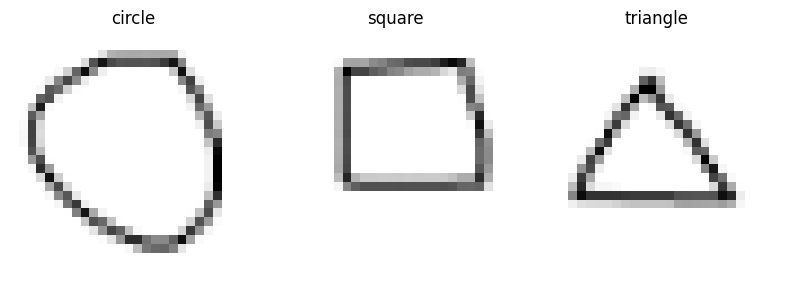

In [3]:
fig, axes = plt.subplots(1, len(class_names), figsize=(8, 3))
for ax, label in zip(axes, class_names):
    path = df.loc[df['label'] == label, 'filepath'].iloc[0]
    img = tf.io.decode_png(tf.io.read_file(path), channels=1)
    ax.imshow(img[:, :, 0], cmap='gray')
    ax.set_title(label)
    ax.axis('off')
plt.tight_layout()
plt.show()

Pripravimo funkcijo za nalaganje slik v sivinski obliki dimenzije 28 x 28 x 1 in normalizacijo vrednosti pikslov na interval [0, 1], pomožno funkcijo za gradnjo cevovodov `tf.data.Dataset` ter 5 enakih stratificiranih prečnih rezov (z delitvijo na učno, validacijsko in testno množico).

In [4]:
def load_image(path, label):
    img = tf.io.read_file(path)
    img = tf.io.decode_png(img, channels=1)  # 1 kanal = sivinska slika
    img = tf.image.resize(img, [28, 28])  # staticna oblika (28, 28, 1) za model
    img = img / 255.0  # normalizacija pikslov na interval [0, 1]
    return img, label

def make_dataset(file_paths, labels, batch_size=32, shuffle=False):
    ds = tf.data.Dataset.from_tensor_slices((file_paths, labels))
    ds = ds.map(load_image, num_parallel_calls=tf.data.AUTOTUNE)
    if shuffle:
        # mesamo samo ucne podatke na vsako epoho
        ds = ds.shuffle(len(file_paths), seed=SEED, reshuffle_each_iteration=True)
    return ds.batch(batch_size).prefetch(tf.data.AUTOTUNE)  # pripravi naslednji paketek v ozadju

sample_x, sample_y = next(iter(make_dataset(paths, y, batch_size=32, shuffle=False)))
print('Oblika paketka:', sample_x.shape, sample_x.dtype)
print('Obseg vrednosti:', float(tf.reduce_min(sample_x)), '-', float(tf.reduce_max(sample_x)))

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
folds = []
for train_val_idx, test_idx in skf.split(paths, y):
    # v vsakem rezu: 192 ucnih, 48 validacijskih (nadzor/ustavljanje), 60 testnih slik
    train_idx, val_idx = train_test_split(
        train_val_idx, test_size=0.2, stratify=y[train_val_idx], random_state=SEED
    )
    folds.append((train_idx, val_idx, test_idx))

print(f'Velikosti mnozic (1. rez): ucenje={len(folds[0][0])}, validacija={len(folds[0][1])}, test={len(folds[0][2])}')

Oblika paketka: (32, 28, 28, 1) <dtype: 'float32'>
Obseg vrednosti: 0.05882352963089943 - 1.0
Velikosti mnozic (1. rez): ucenje=192, validacija=48, test=60


## 2. Podatkovna augmentacija

Definiramo sklop dveh smiselnih naključnih transformacij (zrcaljenje v vodoravni in navpični smeri ter zmerni premik ob ohranjanju belega ozadja `fill_value=1.0`), ki se izvajata izključno med učenjem in ohranjata pravilno oznako lika, nato pa prikažemo nekaj primerov izvirnih in augmentiranih slik.

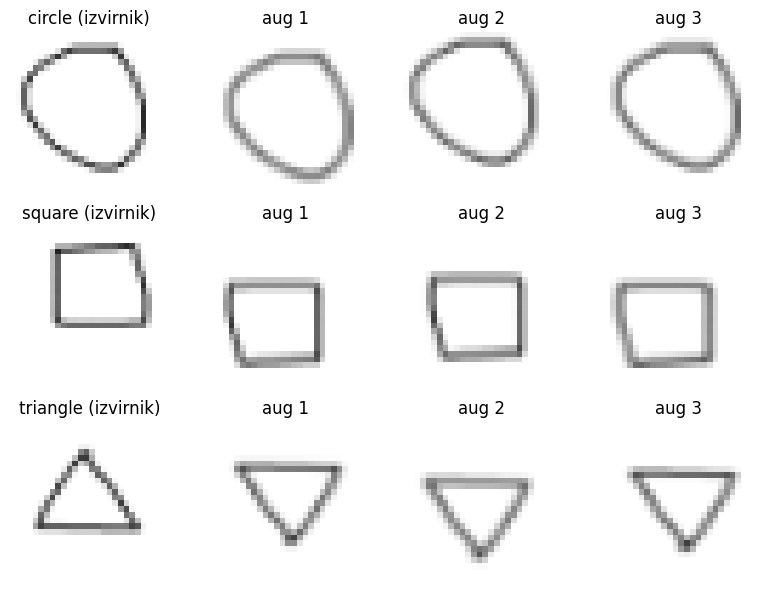

In [5]:
def make_augmentation():
    return keras.Sequential([
        layers.RandomFlip('horizontal_and_vertical'),  # zrcaljenje ohranja razred lika
        layers.RandomTranslation(0.06, 0.06, fill_mode='constant', fill_value=1.0),  # 1.0 = belo ozadje brez crnih robov
    ], name='augmentation')

aug_preview = make_augmentation()
fig, axes = plt.subplots(len(class_names), 4, figsize=(8, 6))
for row, label in enumerate(class_names):
    path = df.loc[df['label'] == label, 'filepath'].iloc[0]
    img, _ = load_image(path, 0)
    axes[row, 0].imshow(img[:, :, 0], cmap='gray', vmin=0, vmax=1)
    axes[row, 0].set_title(f'{label} (izvirnik)')
    axes[row, 0].axis('off')
    for col in range(1, 4):
        aug_img = aug_preview(img[None, ...], training=True)[0]
        axes[row, col].imshow(aug_img[:, :, 0], cmap='gray', vmin=0, vmax=1)
        axes[row, col].set_title(f'aug {col}')
        axes[row, col].axis('off')
plt.tight_layout()
plt.show()

## 3. Izgradnja konvolucijskih nevronskih mrež

Pripravimo funkciji za gradnjo referenčnega modela CNN in lastnega prilagojenega modela CNN, nato pa izpišemo povzetek obeh arhitektur ter primerjamo število učljivih parametrov.

Pri prilagojeni arhitekturi v primerjavi z referenčnim modelom spremenimo naslednje elemente:
- **Globina in število filtrov**: namesto dveh konvolucijskih slojev s po 16 filtri uporabimo tri konvolucijske bloke s progresivnim številom filtrov (16, 32 in 64) ter dodatnim združevalnim slojem `MaxPooling2D(2x2)` za boljše hierarhično zaznavanje robov, kotov in celotnih oblik.
- **Zmanjšan polno povezani sloj in regularizacija**: sloj `Dense` zmanjšamo s 64 na 32 nevronov ter dodamo `Dropout(0.25)` in regularizacijo `L2(1e-4)` za omejevanje preprileganja na manjši zbirki slik.
- **Hiperparametri učenja**: uporabimo hitrost učenja `learning_rate=0.002` in velikost paketka `batch_size=16`, kar na 192 učnih slikah omogoči dvakrat več posodobitev uteži na epoho in hitrejšo konvergenco ob podatkovni augmentaciji.

In [6]:
def build_reference_cnn(use_augmentation=False):
    model_layers = [layers.Input(shape=(28, 28, 1))]
    if use_augmentation:
        model_layers.append(make_augmentation())  # aktivno samo med ucenjem (training=True)
    model_layers.extend([
        layers.Conv2D(16, (3, 3), padding='same', activation='relu'),  # 16 filtrov 3x3; 'same' ohrani velikost 28x28
        layers.MaxPooling2D((2, 2)),  # prepolovi velikost slike (28 -> 14)
        layers.Conv2D(16, (3, 3), padding='same', activation='relu'),
        layers.MaxPooling2D((2, 2)),  # 14 -> 7
        layers.Flatten(),  # splosci 7x7x16 v vektor 784
        layers.Dense(64, activation='relu'),  # vecina parametrov modela (50.240)
        layers.Dense(3, activation='softmax'),  # 3 izhodi kot verjetnosti razredov
    ])
    model = keras.Sequential(model_layers, name='referencni_cnn')
    model.compile(
        optimizer=keras.optimizers.Adam(),  # privzeta ucna stopnja lr=0.001
        loss='sparse_categorical_crossentropy',  # za celostevilske oznake 0, 1, 2
        metrics=['accuracy'],
    )
    return model

def build_custom_cnn(use_augmentation=True):
    model_layers = [layers.Input(shape=(28, 28, 1))]
    if use_augmentation:
        model_layers.append(make_augmentation())
    model_layers.extend([
        layers.Conv2D(16, (3, 3), padding='same', activation='relu'),
        layers.MaxPooling2D((2, 2)),  # 28 -> 14
        layers.Conv2D(32, (3, 3), padding='same', activation='relu'),  # vec filtrov za kompleksnejse vzorce
        layers.MaxPooling2D((2, 2)),  # 14 -> 7
        layers.Conv2D(64, (3, 3), padding='same', activation='relu'),  # 3. konvolucijski blok (16 -> 32 -> 64)
        layers.MaxPooling2D((2, 2)),  # 7 -> 3; zmanjsa vektor pred Dense
        layers.Flatten(),  # 3x3x64 = 576
        layers.Dropout(0.25),  # izklopi 25 % aktivacij proti preprileganju
        layers.Dense(32, activation='relu', kernel_regularizer=regularizers.l2(1e-4)),  # manjsi Dense + kazen L2
        layers.Dense(3, activation='softmax'),
    ])
    model = keras.Sequential(model_layers, name='prilagojeni_cnn')
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=0.002),  # vecji korak za hitrejso konvergenco ob augmentaciji
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy'],
    )
    return model

ref_model = build_reference_cnn(use_augmentation=False)
custom_model = build_custom_cnn(use_augmentation=False)

ref_model.summary()
print()
custom_model.summary()
print(f'\nPrimerjava parametrov: referencni={ref_model.count_params()}, prilagojeni={custom_model.count_params()}')

Model: "referencni_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 28, 28, 16)     │           160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 14, 14, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 14, 14, 16)     │         2,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 7, 7, 16)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │        50,240 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 3)              │           195 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 52,915 (206.70 KB)

 Trainable params: 52,915 (206.70 KB)

 Non-trainable params: 0 (0.00 B)

Model: "prilagojeni_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_2 (Conv2D)               │ (None, 28, 28, 16)     │           160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 14, 14, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 14, 14, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 7, 7, 32)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 7, 7, 64)       │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 3, 3, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 576)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 576)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │        18,464 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 3)              │            99 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 41,859 (163.51 KB)

 Trainable params: 41,859 (163.51 KB)

 Non-trainable params: 0 (0.00 B)


Primerjava parametrov: referencni=52915, prilagojeni=41859


## 4. Učenje modelov s 5-kratno prečno validacijo

Vse tri konfiguracije (A: referenčni CNN brez augmentacije, B: referenčni CNN z augmentacijo, C: prilagojeni CNN z augmentacijo in regularizacijo) naučimo na enakih 5 prečnih rezih z največ 50 epohami, zgodnjim ustavljanjem (`EarlyStopping` na `val_loss` z obnovitvijo najboljših uteži) in shranjevanjem zgodovine učenja ter testnih napovedi.

In [7]:
configs = {
    'A: Referencni CNN': (lambda: build_reference_cnn(use_augmentation=False), 32),  # batch=32 (6 korakov/epoho)
    'B: Referencni CNN + augmentacija': (lambda: build_reference_cnn(use_augmentation=True), 32),
    'C: Prilagojeni CNN': (lambda: build_custom_cnn(use_augmentation=True), 16),  # batch=16 (12 korakov/epoho)
}

histories = {name: [] for name in configs}
results = {name: [] for name in configs}
fold0_preds = {}

for name, (builder, batch_size) in configs.items():
    print(f'=== {name} ===')
    for fold_idx, (train_idx, val_idx, test_idx) in enumerate(folds):
        keras.backend.clear_session()  # svez model brez prenosa utezi med rezi
        tf.keras.utils.set_random_seed(SEED + fold_idx)

        train_ds = make_dataset(paths[train_idx], y[train_idx], batch_size=batch_size, shuffle=True)
        val_ds = make_dataset(paths[val_idx], y[val_idx], batch_size=batch_size, shuffle=False)
        test_ds = make_dataset(paths[test_idx], y[test_idx], batch_size=batch_size, shuffle=False)

        model = builder()
        early_stop = keras.callbacks.EarlyStopping(
            monitor='val_loss', patience=10, restore_best_weights=True  # ustavi ob zastoju val_loss in vrne najboljse utezi
        )
        history = model.fit(
            train_ds,
            validation_data=val_ds,
            epochs=50,
            callbacks=[early_stop],
            verbose=0,
            shuffle=False,  # train_ds se ze sam mesa vsako epoho
        )
        histories[name].append(history.history)

        y_true = y[test_idx]
        y_pred = np.argmax(model.predict(test_ds, verbose=0), axis=1)

        acc = accuracy_score(y_true, y_pred)
        prec = precision_score(y_true, y_pred, average='weighted', zero_division=0)
        rec = recall_score(y_true, y_pred, average='weighted', zero_division=0)
        f1 = f1_score(y_true, y_pred, average='weighted', zero_division=0)

        results[name].append({
            'Accuracy': acc,
            'Weighted Precision': prec,
            'Weighted Recall': rec,
            'Weighted F1-score': f1,
        })

        if fold_idx == 0:
            fold0_preds[name] = (y_true, y_pred)

        ep = len(history.history['loss'])
        print(f'  Rez {fold_idx + 1}: epoh={ep:2d}, Accuracy={acc:.3f}, Weighted F1={f1:.3f}')

=== A: Referencni CNN ===

  Rez 1: epoh=50, Accuracy=0.767, Weighted F1=0.762
  Rez 2: epoh=50, Accuracy=0.783, Weighted F1=0.783
  Rez 3: epoh=50, Accuracy=0.883, Weighted F1=0.883
  Rez 4: epoh=50, Accuracy=0.783, Weighted F1=0.774
  Rez 5: epoh=50, Accuracy=0.917, Weighted F1=0.917
=== B: Referencni CNN + augmentacija ===
  Rez 1: epoh=50, Accuracy=0.750, Weighted F1=0.745
  Rez 2: epoh=50, Accuracy=0.750, Weighted F1=0.741
  Rez 3: epoh=50, Accuracy=0.867, Weighted F1=0.868
  Rez 4: epoh=50, Accuracy=0.767, Weighted F1=0.765
  Rez 5: epoh=50, Accuracy=0.950, Weighted F1=0.951
=== C: Prilagojeni CNN ===
  Rez 1: epoh=50, Accuracy=0.933, Weighted F1=0.931
  Rez 2: epoh=50, Accuracy=0.817, Weighted F1=0.819
  Rez 3: epoh=50, Accuracy=0.967, Weighted F1=0.967
  Rez 4: epoh=50, Accuracy=0.967, Weighted F1=0.967
  Rez 5: epoh=50, Accuracy=0.917, Weighted F1=0.915


## 5. Analiza učnih krivulj

Za prvi prečni rez prikažemo potek učne in validacijske točnosti (`accuracy`, `val_accuracy`) ter funkcije izgube (`loss`, `val_loss`) za vse tri konfiguracije.

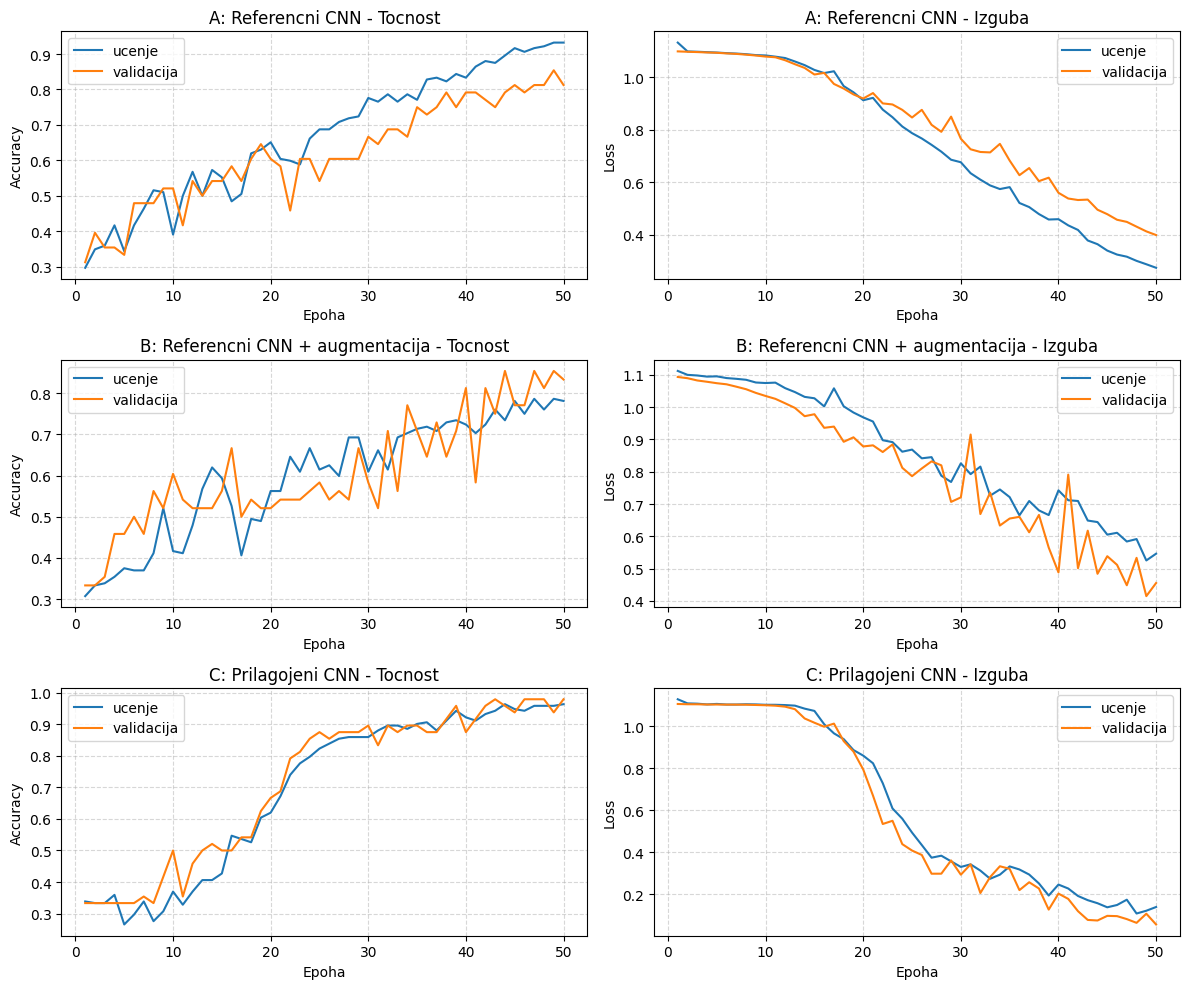

In [8]:
fig, axes = plt.subplots(len(configs), 2, figsize=(12, 10))
for row, name in enumerate(configs):
    hist = histories[name][0]
    epochs_range = range(1, len(hist['loss']) + 1)

    axes[row, 0].plot(epochs_range, hist['accuracy'], label='ucenje')
    axes[row, 0].plot(epochs_range, hist['val_accuracy'], label='validacija')
    axes[row, 0].set_title(f'{name} - Tocnost')
    axes[row, 0].set_xlabel('Epoha')
    axes[row, 0].set_ylabel('Accuracy')
    axes[row, 0].legend()
    axes[row, 0].grid(True, linestyle='--', alpha=0.5)

    axes[row, 1].plot(epochs_range, hist['loss'], label='ucenje')
    axes[row, 1].plot(epochs_range, hist['val_loss'], label='validacija')
    axes[row, 1].set_title(f'{name} - Izguba')
    axes[row, 1].set_xlabel('Epoha')
    axes[row, 1].set_ylabel('Loss')
    axes[row, 1].legend()
    axes[row, 1].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

### Ugotovitve iz učnih krivulj (1. prečni rez)

- **A (Referenčni CNN)**: Učenje poteka skozi vseh 50 epoh, saj se validacijska izguba enakomerno znižuje do konca (približno z 1,10 na 0,40). Po 25. epohi pa se začne kazati razkorak med učno točnostjo (~0,93 v 50. epohi) in validacijsko točnostjo (~0,81–0,85), kar kaže na začetek preprileganja manjši učni množici.
- **B (Referenčni CNN + augmentacija)**: Naključno zrcaljenje in premiki med učenjem otežijo pomnjenje učnih slik, zato učna točnost (~0,78) ostaja pod validacijsko (~0,83–0,85), učna izguba (~0,55) pa nad validacijsko (~0,45). Zaradi majhnega števila posodobitev na epoho (`batch_size=32`, 6 korakov na epoho) in večje raznolikosti slik model v 50 epohah konvergira počasneje in bolj valovito.
- **C (Prilagojeni CNN)**: Po začetni fazi prvih ~13 epoh začneta tako učna kot validacijska izguba strmo padati (z ~1,05 pod 0,30 do 30. epohe) in do 50. epohe dosežeta približno 0,14 (učenje) ter 0,07 (validacija). Krivulji točnosti se tesno ujemata in brez znakov preprileganja presežeta 0,95, k čemur prispevajo večja globina filtrov (16 -> 32 -> 64), pogostejše posodobitve uteži (`batch_size=16`, `learning_rate=0.002`) ter regularizacija (`Dropout` in `L2`).

## 6. Ovrednotenje in primerjava modelov

Izračunamo povprečje in standardni odklon vseh štirih metrik po petih prečnih rezih, rezultate prikažemo v primerjalni tabeli ter izrišemo primerjalne grafe boxplot.

,Konfiguracija,Accuracy,Weighted Precision,Weighted Recall,Weighted F1-score
0,A: Referencni CNN,0.827 +- 0.068,0.832 +- 0.065,0.827 +- 0.068,0.824 +- 0.071
1,B: Referencni CNN + augmentacija,0.817 +- 0.089,0.823 +- 0.090,0.817 +- 0.089,0.814 +- 0.092
2,C: Prilagojeni CNN,0.920 +- 0.062,0.924 +- 0.061,0.920 +- 0.062,0.920 +- 0.061


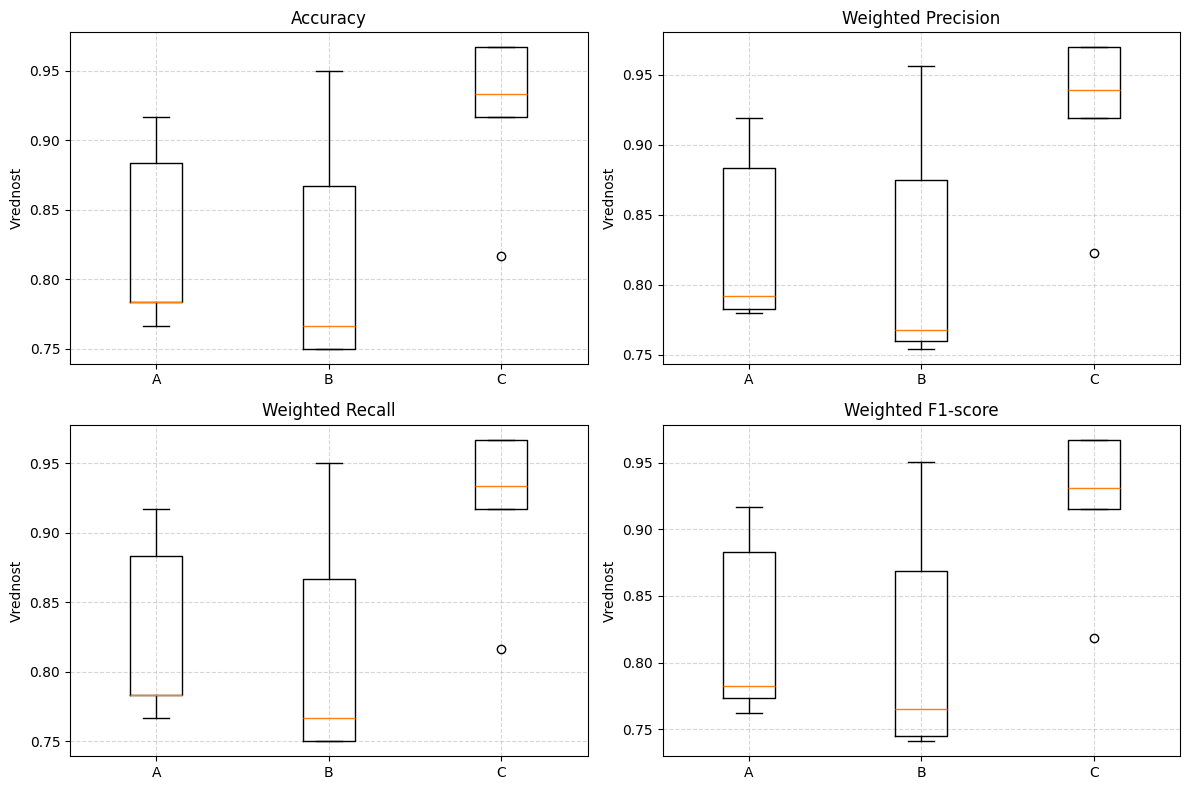

In [9]:
metric_names = ['Accuracy', 'Weighted Precision', 'Weighted Recall', 'Weighted F1-score']
summary_rows = []
for name in configs:
    df_res = pd.DataFrame(results[name])
    row = {'Konfiguracija': name}
    for m in metric_names:
        row[m] = f'{df_res[m].mean():.3f} +- {df_res[m].std():.3f}'
    summary_rows.append(row)

summary_df = pd.DataFrame(summary_rows)
display(summary_df)

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
short_labels = ['A', 'B', 'C']
for idx, m in enumerate(metric_names):
    ax = axes[idx // 2, idx % 2]
    data = [[r[m] for r in results[name]] for name in configs]
    ax.boxplot(data, tick_labels=short_labels)
    ax.set_title(m)
    ax.set_ylabel('Vrednost')
    ax.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

Za prvi prečni rez izrišemo matrike zmede vseh treh konfiguracij, da preučimo najpogostejše napake pri razvrščanju posameznih oblik.

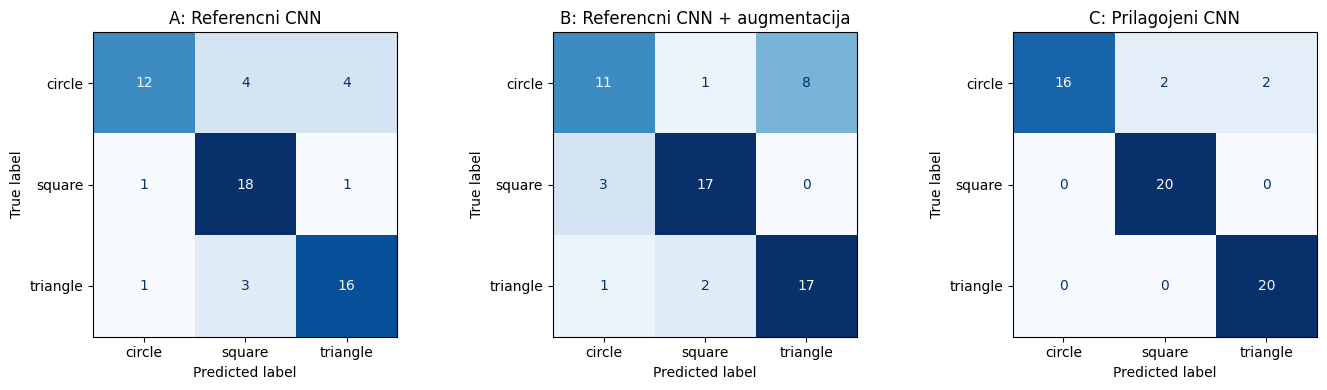

In [10]:
fig, axes = plt.subplots(1, len(configs), figsize=(14, 4))
for ax, name in zip(axes, configs):
    y_true, y_pred = fold0_preds[name]
    ConfusionMatrixDisplay.from_predictions(
        y_true, y_pred, display_labels=class_names, cmap='Blues', ax=ax, colorbar=False
    )
    ax.set_title(name)
plt.tight_layout()
plt.show()

### Interpretacija rezultatov

- **Primerjava konfiguracij (5-kratna prečna validacija)**:
  - **A (Referenčni CNN)** doseže povprečno točnost `0.827 +- 0.068` in uteženo F1-vrednost `0.824 +- 0.071`. Kljub preprosti zgradbi (52.915 parametrov, od tega kar 50.240 v polno povezanem sloju `Dense(64)`) dobro loči osnovne oblike, vendar se razlika po posameznih rezih giblje med 0,767 in 0,917.
  - **B (Referenčni CNN + augmentacija)** doseže povprečno točnost `0.817 +- 0.089` in F1 `0.814 +- 0.092`. Na 5. rezu se povzpne do 0,950, vendar ima večji razpon po rezih (0,750–0,950), ker plitvejša mreža z `batch_size=32` pri omejitvi na 50 epoh še ne izkoristi v celoti povečane raznolikosti augmentiranih slik.
  - **C (Prilagojeni CNN)** doseže najboljše in najbolj stabilne rezultate na vseh metrikah: točnost **`0.920 +- 0.062`**, uteženo preciznost **`0.924 +- 0.061`**, priklic **`0.920 +- 0.062`** in F1 **`0.920 +- 0.061`** (na 3. in 4. rezu kar 0,967). Kljub manjšemu skupnemu številu parametrov (41.859 proti 52.915) premakne večji delež kapacitete v tri konvolucijske bloke (`16 -> 32 -> 64`), kar ob regularizaciji (`Dropout`, `L2`) ter pogostejših posodobitvah uteži omogoči bistveno boljšo posplošitev.
- **Analiza napak na matrikah zmede (1. rez, 60 testnih slik)**:
  - Pri konfiguraciji **A** (46/60 pravilnih) so največja težava krogi (`circle`), kjer jih je 8 od 20 napačno razvrščenih (4 kot kvadrat, 4 kot trikotnik), trikrat pa je trikotnik zamenjan za kvadrat.
  - Pri konfiguraciji **B** (45/60 pravilnih) model pravilno prepozna po 17 kvadratov in trikotnikov, pri krogih pa jih 8 zamenja za trikotnik.
  - Pri konfiguraciji **C** (56/60 pravilnih) model brez ene same napake prepozna vseh 20 kvadratov in vseh 20 trikotnikov, edine 4 napake pa nastanejo pri ročno narisanih krogih z nekoliko bolj oglatimi obrisi (2 zamenjana s kvadratom, 2 s trikotnikom).